In [ ]:
# Setup
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers==4.40.0 accelerate sentencepiece

import os, numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from scipy.stats import pearsonr

DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"
DEBERTA_WEIGHTS    = "/content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt"
DATA_PATH          = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_text_FULLY_PRUNED.csv"
SENTIMENT_NORM     = 3.0
MAX_LEN            = 128
BATCH_SIZE         = 16
EMOTION_COLS       = ["happy", "sad", "anger", "fear", "disgust", "surprise"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

In [ ]:
import os, sys

!pip install -q timm==0.4.12 einops decord

# Audio (wav) flatten
WAV_FLAT = "/content/MOSEI_wav_flat"
if not os.path.exists(WAV_FLAT) or len(os.listdir(WAV_FLAT)) == 0:
    !unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" -d /content/MOSEI_wav
    !find /content/MOSEI_wav -name "._*" -delete
    !rm -rf /content/MOSEI_wav/__MACOSX
    import shutil
    SRC = "/content/MOSEI_wav/Raw_Wav"
    os.makedirs(WAV_FLAT, exist_ok=True)
    for vid in os.listdir(SRC):
        p = os.path.join(SRC, vid)
        if not os.path.isdir(p): continue
        for fname in os.listdir(p):
            if fname.endswith(".wav"):
                shutil.copy2(os.path.join(p, fname),
                              os.path.join(WAV_FLAT, f"{vid}__{fname.replace('.wav','')}.wav"))
    print(f"Flattened {len(os.listdir(WAV_FLAT))} wavs")
else:
    print(f"WAV flat dir present: {len(os.listdir(WAV_FLAT))} files")

# Video (mp4) flatten
MP4_FLAT = "/content/MOSEI_faces_flat"
if not os.path.exists(MP4_FLAT) or len(os.listdir(MP4_FLAT)) == 0:
    !unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw-Cropped-FULL.zip" -d /content/MOSEI_faces
    !find /content/MOSEI_faces -name "._*" -delete
    !rm -rf /content/MOSEI_faces/__MACOSX
    import shutil
    SRC = "/content/MOSEI_faces/Raw-Cropped-FULL"
    os.makedirs(MP4_FLAT, exist_ok=True)
    for vid in os.listdir(SRC):
        p = os.path.join(SRC, vid)
        if not os.path.isdir(p): continue
        for fname in os.listdir(p):
            if fname.endswith(".mp4"):
                shutil.copy2(os.path.join(p, fname),
                              os.path.join(MP4_FLAT, f"{vid}__{fname}"))
    print(f"Flattened {len(os.listdir(MP4_FLAT))} mp4s")
else:
    print(f"MP4 flat dir present: {len(os.listdir(MP4_FLAT))} files")

# MAE-DFER repo
if not os.path.exists("/content/MAE-DFER"):
    !git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER

sys.path.insert(0, '/content/MAE-DFER')
import modeling_finetune
from timm.models import create_model

print("Setup cell done.")

Flattened 22856 wavs
Flattened 22856 mp4s
Setup cell done.


In [ ]:
# Imports + hyperparameters
import os, gc, random, shutil, copy, contextlib, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import soundfile as sf
import cv2
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoModel, AutoTokenizer, AutoFeatureExtractor,
    HubertModel, get_cosine_schedule_with_warmup,
)
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr

# Paths
ENRICHED_CSV     = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv"
PREPROCESSED_CSV = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_text_FULLY_PRUNED.csv"
FLAT_WAV_DIR     = "/content/MOSEI_wav_flat"
FLAT_MP4_DIR     = "/content/MOSEI_faces_flat"
OUTPUT_DIR       = "/content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v61-clean"
os.makedirs(OUTPUT_DIR, exist_ok=True)

HUBERT_WEIGHTS   = "/content/drive/Shareddrives/AI Capstone/Audio Models/hubert-mosei-multitask-llrd/best_model.pt"
DEBERTA_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt"
MAEDFER_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints (Final Model)/best_model.pt"
MAEDFER_PRETRAIN = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Pretrained/checkpoint-49.pth"

HUBERT_CHECKPOINT  = "facebook/hubert-base-ls960"
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

HUBERT_DIM  = 768
DEBERTA_DIM = 768
MAEDFER_DIM = 512

NUM_FRAMES    = 16
IMAGE_SIZE    = 160
VIDEO_MEAN    = [0.5, 0.5, 0.5]
VIDEO_STD     = [0.5, 0.5, 0.5]
SAMPLE_RATE   = 16_000
MAX_AUDIO_LEN = int(8.0 * SAMPLE_RATE)
MAX_TEXT_LEN  = 128

BATCH_SIZE       = 16
GRAD_ACCUM       = 2
MAX_EPOCHS       = 200
PATIENCE         = 15
LR_FUSION        = 5e-5
WD               = 0.01
WARMUP_RATIO     = 0.05
SEED             = 42
D_MODEL          = 256
NUM_HEADS        = 8
DROPOUT_PROB     = 0.35
CCC_ALPHA        = 0.6
LABEL_SMOOTHING  = 0.05
SENTIMENT_WEIGHT = 1.0
EMOTION_WEIGHT   = 1.0
POOL_LEN         = 16

# Mixture init logits [text, audio, video, fuse]
MIXTURE_INIT_SENT = [ 0.0, -1.3, -2.4, -0.8]
MIXTURE_INIT_EMOT = [-1.3,  0.0, -2.4, -0.8]

EMOTION_COLS      = ["happy", "sad", "anger", "fear", "disgust", "surprise"]
EMOTION_THRESHOLD = 0.5
V6_BEST_AVG_CCC   = 0.4307

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
import transformers
print(f"transformers: {transformers.__version__}")

Device: cuda
GPU  : NVIDIA A100-SXM4-40GB
VRAM : 42.4 GB
transformers: 4.40.0


In [ ]:
# Metrics & losses
def ccc_np(y_true, y_pred):
    y_true = np.array(y_true, dtype=np.float64)
    y_pred = np.array(y_pred, dtype=np.float64)
    if np.std(y_true) < 1e-8 or np.std(y_pred) < 1e-8:
        return 0.0, 0.0
    rho, _    = pearsonr(y_true, y_pred)
    std_t, std_p = np.std(y_true), np.std(y_pred)
    mean_t, mean_p = np.mean(y_true), np.mean(y_pred)
    num = 2.0 * rho * std_t * std_p
    den = std_t**2 + std_p**2 + (mean_t - mean_p)**2
    return float(num / den if den > 1e-8 else 0.0), float(rho)


def ccc_loss_single(pred, target):
    mp, mt = pred.mean(), target.mean()
    cov    = ((pred - mp) * (target - mt)).mean()
    sp, st = pred.std(), target.std()
    if st < 1e-3 or sp < 1e-3:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    den = sp**2 + st**2 + (mp - mt)**2 + 1e-4
    return 1.0 - (2.0 * cov) / den


def sentiment_loss(pred, target, alpha=CCC_ALPHA):
    return alpha * ccc_loss_single(pred, target) + (1.0 - alpha) * F.mse_loss(pred, target)


def emotion_loss(pred, target, emotion_weights, alpha=CCC_ALPHA, smoothing=LABEL_SMOOTHING):
    target_smooth = target * (1.0 - smoothing) + 0.5 * smoothing
    ccc = torch.stack([
        ccc_loss_single(pred[:, i], target[:, i]) * emotion_weights[i]
        for i in range(pred.shape[1])
    ]).mean()
    w   = emotion_weights.unsqueeze(0).expand_as(pred)
    bce = F.binary_cross_entropy(pred.clamp(1e-6, 1 - 1e-6),
                                  target_smooth.clamp(0, 1), weight=w)
    return alpha * ccc + (1.0 - alpha) * bce


In [ ]:
# Load labels + preprocessed-text merge
df = pd.read_csv(ENRICHED_CSV)
df["video_id"] = df["video_id"].astype(str)
df["clip_id"]  = df["clip_id"].astype(str)
df["wav_path"] = df.apply(lambda r: f"{FLAT_WAV_DIR}/{r['video_id']}__{r['clip_id']}.wav", axis=1)
df["mp4_path"] = df.apply(lambda r: f"{FLAT_MP4_DIR}/{r['video_id']}__{r['clip_id']}.mp4", axis=1)

before = len(df)
df = df[df["wav_path"].apply(os.path.exists) & df["mp4_path"].apply(os.path.exists)].copy()
print(f"Loaded {before} rows → kept {len(df)} with matching files")

df["sentiment_norm"] = df["sentiment"].clip(-3, 3) / 3.0
for col in EMOTION_COLS:
    df[col] = df[col].clip(0, 1)

# Corrected join: match on label tuple + within-key position
df_uni = pd.read_csv(PREPROCESSED_CSV)
df_uni = df_uni.dropna(subset=['text'])
df_uni['text'] = df_uni['text'].astype(str).str.strip()
df_uni = df_uni[df_uni['text'] != ''].reset_index(drop=True)

key_cols = ['mode', 'sentiment', 'happy', 'sad', 'anger', 'fear', 'disgust', 'surprise']

df = df.reset_index(drop=True)
df['_pos_in_key']     = df.groupby(key_cols).cumcount()
df_uni['_pos_in_key'] = df_uni.groupby(key_cols).cumcount()

df_uni_subset = df_uni[key_cols + ['_pos_in_key', 'text']].rename(columns={'text': 'text_preprocessed'})

before = len(df)
df = df.merge(df_uni_subset, on=key_cols + ['_pos_in_key'], how='left').drop(columns=['_pos_in_key'])
after = len(df)
print(f"Merge: {before} → {after} rows (should be equal)")
print(f"Rows with preprocessed text: {df['text_preprocessed'].notna().sum()}")
print(f"Rows missing: {df['text_preprocessed'].isna().sum()}")

df = df[df['text_preprocessed'].notna()].reset_index(drop=True)

train_df = df[df["mode"] == "train"].reset_index(drop=True)
val_df   = df[df["mode"] == "valid"].reset_index(drop=True)
test_df  = df[df["mode"] == "test"].reset_index(drop=True)
print(f"After drop: Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")

# Sanity-check alignment
print("\nVerifying test alignment after corrected join:")
for i in [0, 100, 1000, 2000, 3000, 4100]:
    if i < len(test_df):
        sent = test_df.iloc[i]['sentiment']
        orig = test_df.iloc[i]['text'][:50]
        prep = test_df.iloc[i]['text_preprocessed']
        print(f"  row {i}: sent={sent:.2f}")
        print(f"    orig: {orig}")
        print(f"    prep: {prep[:60]}")

EMOTION_WEIGHTS = torch.ones(6, dtype=torch.float32).to(device)
print("\nEmotion weights: uniform (all 1.0)")

Loaded 19970 rows → kept 19970 with matching files
Merge: 19970 → 19970 rows (should be equal)
Rows with preprocessed text: 15811
Rows missing: 4159
After drop: Train: 11096  Val: 1409  Test: 3306

Verifying test alignment after corrected join:
  row 0: sent=0.33
    orig: So the answer to the question, can I contribute st
    prep: answer question contribute stock ira absolutely correct alwa
  row 100: sent=0.33
    orig: And if you enjoyed the previous two DVDs, you have
    prep: enjoyed previous two dvds continue story
  row 1000: sent=1.33
    orig: And our sponsor, and having Cengage sponsor us has
    prep: sponsor cengage sponsor us helped
  row 2000: sent=0.33
    orig: -The report ranks major US retailers according to 
    prep: -the report ranks major us retailers according sustainable s
  row 3000: sent=0.33
    orig: We use open loop control, which allows quick imple
    prep: use open loop control allows quick implementation without us

Emotion weights: uniform (all 1.0)


In [ ]:
# Dataset & DataLoaders
audio_feature_extractor = AutoFeatureExtractor.from_pretrained(HUBERT_CHECKPOINT)
text_tokenizer          = AutoTokenizer.from_pretrained(DEBERTA_CHECKPOINT)
video_mean = np.array(VIDEO_MEAN, dtype=np.float32)
video_std  = np.array(VIDEO_STD,  dtype=np.float32)


def load_video_frames(mp4_path, num_frames=NUM_FRAMES, image_size=IMAGE_SIZE):
    cap   = cv2.VideoCapture(mp4_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release()
        return torch.zeros(3, num_frames, image_size, image_size)
    indices = np.linspace(0, total - 1, num_frames, dtype=int)
    frames  = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (image_size, image_size))
        else:
            frame = np.zeros((image_size, image_size, 3), dtype=np.uint8)
        frame = ((frame.astype(np.float32) / 255.0) - video_mean) / video_std
        frames.append(frame)
    cap.release()
    return torch.from_numpy(np.stack(frames, axis=0)).permute(3, 0, 1, 2)


class MOSEIFusionDataset(Dataset):
    def __init__(self, df): self.df = df
    def __len__(self):       return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:   audio, _ = sf.read(row["wav_path"], dtype="float32")
        except: audio   = np.zeros(MAX_AUDIO_LEN, dtype=np.float32)
        if len(audio) > MAX_AUDIO_LEN:
            audio = audio[:MAX_AUDIO_LEN]
        text  = str(row["text_preprocessed"]) if pd.notna(row.get("text_preprocessed")) else str(row["text"])
        video = load_video_frames(row["mp4_path"])
        return (audio, text, video,
                float(row["sentiment_norm"]),
                [float(row[c]) for c in EMOTION_COLS])


def collate_fn(batch):
    audios, texts, videos, sentiments, emotions = zip(*batch)
    audio_inputs = audio_feature_extractor(
        list(audios), sampling_rate=SAMPLE_RATE, max_length=MAX_AUDIO_LEN,
        truncation=True, padding="max_length", return_tensors="pt")
    text_inputs = text_tokenizer(
        list(texts), padding="max_length", truncation=True,
        max_length=MAX_TEXT_LEN, return_tensors="pt")
    return {
        "input_values":     audio_inputs["input_values"],
        "input_ids":        text_inputs["input_ids"],
        "attention_mask":   text_inputs["attention_mask"],
        "pixel_values":     torch.stack(list(videos)),
        "sentiment_labels": torch.tensor(sentiments, dtype=torch.float32),
        "emotion_labels":   torch.tensor(emotions,   dtype=torch.float32),
    }


train_loader = DataLoader(MOSEIFusionDataset(train_df), batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=8, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(MOSEIFusionDataset(val_df),   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(MOSEIFusionDataset(test_df),  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn, pin_memory=True)
print(f"Batches — train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")


Batches — train: 694  val: 89  test: 207


In [ ]:
# Load backbones (DeBERTa first!)
# 1. DeBERTa FIRST
print("Loading DeBERTa first…")
deberta = AutoModel.from_pretrained(DEBERTA_CHECKPOINT)
state   = torch.load(DEBERTA_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
deberta_state = {k[len("encoder."):]: v for k, v in state.items() if k.startswith("encoder.")}
m, u = deberta.load_state_dict(deberta_state, strict=False)
print(f"  DeBERTa load: {len(m)} missing, {len(u)} unexpected from {len(deberta_state)} keys")
for p in deberta.parameters(): p.requires_grad = False
deberta = deberta.to(device).eval()

# 2. HuBERT
print("Loading HuBERT…")
hubert = HubertModel.from_pretrained(HUBERT_CHECKPOINT)
state  = torch.load(HUBERT_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
hubert_state = {k[len("hubert."):]: v for k, v in state.items() if k.startswith("hubert.")}
m, u = hubert.load_state_dict(hubert_state, strict=False)
print(f"  HuBERT load: {len(m)} missing, {len(u)} unexpected")
for p in hubert.parameters(): p.requires_grad = False
hubert.feature_extractor._requires_grad = False
hubert.config.apply_spec_augment = False
hubert = hubert.to(device).eval()

# 3. MAE-DFER
print("Loading MAE-DFER…")
class MAEDFERBackbone(nn.Module):
    def __init__(self, pretrain_ckpt):
        super().__init__()
        self.backbone = create_model(
            'vit_base_dim512_no_depth_patch16_160',
            pretrained=False, num_classes=7, all_frames=NUM_FRAMES,
            tubelet_size=2, use_mean_pooling=True,
            attn_type='local_global', lg_region_size=(2, 5, 10),
            lg_first_attn_type='self', lg_third_attn_type='cross',
            lg_attn_param_sharing_first_third=False, lg_attn_param_sharing_all=False,
            lg_classify_token_type='org', lg_no_second=False, lg_no_third=False,
            drop_path_rate=0.1, init_values=0.0,
        )
        self.backbone.head = nn.Identity()
        ckpt = torch.load(pretrain_ckpt, map_location='cpu', weights_only=False)
        self.backbone.load_state_dict(ckpt['model'] if 'model' in ckpt else ckpt, strict=False)
    def forward(self, x): return self.backbone(x)

maedfer  = MAEDFERBackbone(MAEDFER_PRETRAIN)
ft_state = torch.load(MAEDFER_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in ft_state: ft_state = ft_state["model_state_dict"]
maedfer.backbone.load_state_dict(
    {k.replace("backbone.", ""): v for k, v in ft_state.items() if not k.startswith("head.")},
    strict=False)
for p in maedfer.parameters(): p.requires_grad = False
maedfer = maedfer.to(device).eval()

if device.type == "cuda":
    print(f"VRAM after backbones: {torch.cuda.memory_allocated(device)/1e9:.2f} GB")


Loading DeBERTa first…
  DeBERTa load: 0 missing, 0 unexpected from 198 keys
Loading HuBERT…


Some weights of the model checkpoint at facebook/hubert-base-ls960 were not used when initializing HubertModel: ['encoder.pos_conv_embed.conv.weight_g', 'encoder.pos_conv_embed.conv.weight_v']
- This IS expected if you are initializing HubertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing HubertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of HubertModel were not initialized from the model checkpoint at facebook/hubert-base-ls960 and are newly initialized: ['encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for pre

  HuBERT load: 0 missing, 0 unexpected
Loading MAE-DFER…
==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
VRAM after backbones: 3.63 GB


In [ ]:
# Aux heads
class HuBERTAuxHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.attn_pool = nn.Linear(768, 1)
        self.dropout   = nn.Dropout(0.1)
        self.sentiment_head = nn.Sequential(
            nn.Linear(768, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1), nn.Tanh())
        self.emotion_head = nn.Sequential(
            nn.Linear(768, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 6), nn.Sigmoid())
    def forward(self, hidden_states):
        w = F.softmax(self.attn_pool(hidden_states), dim=1)
        pooled = (w * hidden_states).sum(dim=1)
        pooled = self.dropout(pooled)
        return self.sentiment_head(pooled).squeeze(-1), self.emotion_head(pooled)


class DeBERTaAuxHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(768, 256, batch_first=True, bidirectional=True)
        self.sentiment_head = nn.Sequential(
            nn.Linear(512, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1), nn.Tanh())
        self.emotion_head = nn.Sequential(
            nn.Linear(512, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 6), nn.Sigmoid())
    def forward(self, hidden_states):
        gru_out, _ = self.gru(hidden_states)
        pooled     = gru_out.mean(dim=1)
        return self.sentiment_head(pooled).squeeze(-1), self.emotion_head(pooled)


class MAEDFERAuxHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(512, 256), nn.GELU(),
            nn.Dropout(0.2), nn.Linear(256, 7))
    def forward(self, features):
        logits = self.head(features)
        emot   = torch.clamp(torch.relu(logits[:, :6]), 0, 3) / 3.0
        sent   = torch.tanh(logits[:, 6])
        return sent, emot


# Load DeBERTa aux
print("Loading DeBERTa aux head…")
deberta_aux = DeBERTaAuxHead()
state = torch.load(DEBERTA_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
aux_state = {k: v for k, v in state.items() if not k.startswith("encoder.")}
deberta_aux.load_state_dict(aux_state, strict=True)
for p in deberta_aux.parameters(): p.requires_grad = False
deberta_aux = deberta_aux.to(device).eval()
print(f"  Loaded {len(aux_state)} keys")

# Load HuBERT aux
print("Loading HuBERT aux head…")
hubert_aux = HuBERTAuxHead()
state = torch.load(HUBERT_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
aux_state = {k: v for k, v in state.items() if not k.startswith("hubert.")}
hubert_aux.load_state_dict(aux_state, strict=True)
for p in hubert_aux.parameters(): p.requires_grad = False
hubert_aux = hubert_aux.to(device).eval()
print(f"  Loaded {len(aux_state)} keys")

# Load MAE-DFER aux
print("Loading MAE-DFER aux head…")
maedfer_aux = MAEDFERAuxHead()
state = torch.load(MAEDFER_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state: state = state["model_state_dict"]
aux_state = {k: v for k, v in state.items() if k.startswith("head.")}
maedfer_aux.load_state_dict(aux_state, strict=True)
for p in maedfer_aux.parameters(): p.requires_grad = False
maedfer_aux = maedfer_aux.to(device).eval()
print(f"  Loaded {len(aux_state)} keys")

print("\nAux heads ready — all frozen.")


Loading DeBERTa aux head…
  Loaded 16 keys
Loading HuBERT aux head…
  Loaded 10 keys
Loading MAE-DFER aux head…
  Loaded 4 keys

Aux heads ready — all frozen.


In [ ]:
# SANITY CHECK — DeBERTa aux SCCC
print("Sanity-checking DeBERTa aux head on val set…")
all_p, all_t = [], []
with torch.no_grad():
    for batch in val_loader:
        text_feat = deberta(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        ).last_hidden_state.float()
        sent_d, _ = deberta_aux(text_feat)
        all_p.extend(sent_d.cpu().numpy().tolist())
        all_t.extend(batch["sentiment_labels"].cpu().numpy().tolist())

ccc, _ = ccc_np(all_t, all_p)
print(f"\n  DeBERTa aux SCCC on val: {ccc:.4f}  (expected ~0.67)")

if ccc < 0.5:
    print("\n  ✗ FAIL — DeBERTa aux is broken in this runtime too.")
    print("  Stop here. Don't run training; it'll waste hours.")
    raise RuntimeError(f"DeBERTa aux SCCC={ccc:.4f} is below 0.5 — runtime issue persists")
else:
    print(f"\n  ✓ PASS — DeBERTa aux is healthy. Safe to proceed with fusion training.")

# Quick HuBERT aux check too
print("\nSanity-checking HuBERT aux head on val set…")
all_p, all_t = [], []
with torch.no_grad():
    for batch in val_loader:
        audio_feat = hubert(input_values=batch["input_values"].to(device)).last_hidden_state.float()
        sent_h, _  = hubert_aux(audio_feat)
        all_p.extend(sent_h.cpu().numpy().tolist())
        all_t.extend(batch["sentiment_labels"].cpu().numpy().tolist())
ccc_h, _ = ccc_np(all_t, all_p)
print(f"  HuBERT aux SCCC on val: {ccc_h:.4f}  (expected ~0.53)")


Sanity-checking DeBERTa aux head on val set…

  DeBERTa aux SCCC on val: 0.6450  (expected ~0.67)

  ✓ PASS — DeBERTa aux is healthy. Safe to proceed with fusion training.

Sanity-checking HuBERT aux head on val set…
  HuBERT aux SCCC on val: 0.5005  (expected ~0.53)


In [ ]:
# Fusion with sample-conditional gating

class MixtureGate(nn.Module):
    """
    Per-sample softmax gating over [text, audio, video, fuse] sources.
    Inputs: pooled features (B, POOL_LEN, D) per modality.
    Output: weights (B, 4).

    Initialization: final layer biases set to `init_logits`, weights zeroed.
    At step 0 this produces a *constant* softmax(init_logits) identical to
    v6.1's fixed mixture. Training lets the gate learn to deviate per sample.
    """
    def __init__(self, d_model, init_logits, hidden=128, dropout=0.5):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(d_model * 3, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 4),
        )
        # At init: gate produces softmax(init_logits) for every sample
        nn.init.zeros_(self.mlp[-1].weight)
        with torch.no_grad():
            self.mlp[-1].bias.copy_(torch.tensor(init_logits, dtype=torch.float32))

    def forward(self, t_pool, a_pool, v_pool):
        # Pool over the sequence dim if needed
        t = t_pool.mean(dim=1) if t_pool.dim() == 3 else t_pool
        a = a_pool.mean(dim=1) if a_pool.dim() == 3 else a_pool
        v = v_pool.mean(dim=1) if v_pool.dim() == 3 else v_pool
        x = torch.cat([t, a, v], dim=-1)
        return F.softmax(self.mlp(x), dim=-1)


class SequencePool(nn.Module):
    def __init__(self, d_model, pool_len=POOL_LEN):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(pool_len, d_model) * 0.02)
        self.attn    = nn.MultiheadAttention(d_model, num_heads=4,
                                              dropout=0.1, batch_first=True)
        self.norm    = nn.LayerNorm(d_model)
    def forward(self, x):
        B   = x.size(0)
        q   = self.queries.unsqueeze(0).expand(B, -1, -1)
        out, _ = self.attn(q, x, x)
        return self.norm(out)


class TaskFusionPath(nn.Module):
    def __init__(self, d_model, num_heads, out_dim, dropout=0.2):
        super().__init__()
        self.cls_query  = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.cross_attn = nn.MultiheadAttention(d_model, num_heads,
                                                 dropout=0.1, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn   = nn.Sequential(
            nn.Linear(d_model, d_model * 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model))
        self.norm2 = nn.LayerNorm(d_model)
        self.head  = nn.Sequential(
            nn.Linear(d_model, d_model // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model // 2, out_dim))
    def forward(self, t_pool, a_pool, v_pool):
        B   = t_pool.size(0)
        kv  = torch.cat([t_pool, a_pool, v_pool], dim=1)
        cls = self.cls_query.expand(B, -1, -1)
        att, _ = self.cross_attn(cls, kv, kv)
        cls = self.norm1(cls + att)
        cls = self.norm2(cls + self.ffn(cls))
        return self.head(cls.squeeze(1))


class CrossAttnGatedMixtureV61b(nn.Module):
    def __init__(self, d_model=D_MODEL, num_heads=NUM_HEADS, dropout=DROPOUT_PROB):
        super().__init__()
        self.dropout_prob = 0.20
        self.text_proj  = nn.Linear(DEBERTA_DIM, d_model)
        self.audio_proj = nn.Linear(HUBERT_DIM,  d_model)
        self.video_proj = nn.Linear(MAEDFER_DIM, d_model)
        self.text_pool  = SequencePool(d_model, POOL_LEN)
        self.audio_pool = SequencePool(d_model, POOL_LEN)
        self.video_norm = nn.LayerNorm(d_model)
        self.sent_path  = TaskFusionPath(d_model, num_heads, out_dim=1, dropout=dropout)
        self.emot_path  = TaskFusionPath(d_model, num_heads, out_dim=6, dropout=dropout)
        # Sample-conditional gates (replace fixed mixture parameters)
        self.sent_gate  = MixtureGate(d_model, MIXTURE_INIT_SENT)
        self.emot_gate  = MixtureGate(d_model, MIXTURE_INIT_EMOT)

    def _modality_dropout(self, t, a, v):
        if not self.training: return t, a, v
        dev = t.device
        m_t = (torch.rand(1) > self.dropout_prob).float().to(dev)
        m_a = (torch.rand(1) > self.dropout_prob).float().to(dev)
        m_v = (torch.rand(1) > self.dropout_prob).float().to(dev)
        if (m_t + m_a + m_v).item() == 0:
            idx = torch.randint(0, 3, (1,)).item()
            if   idx == 0: m_t = torch.ones(1).to(dev)
            elif idx == 1: m_a = torch.ones(1).to(dev)
            else:          m_v = torch.ones(1).to(dev)
        scale = 3.0 / (m_t + m_a + m_v)
        return t * m_t * scale, a * m_a * scale, v * m_v * scale

    def forward(self, text_feat, video_feat, audio_feat,
                sent_text, emot_text, sent_audio, emot_audio, sent_video, emot_video,
                sentiment_labels=None, emotion_labels=None, emotion_weights=None):
        t = self.text_proj(text_feat)
        a = self.audio_proj(audio_feat)
        v = self.video_proj(video_feat.unsqueeze(1) if video_feat.dim() == 2 else video_feat)
        t_pool = self.text_pool(t)
        a_pool = self.audio_pool(a)
        v_pool = self.video_norm(v).expand(-1, POOL_LEN, -1)

        t_d, a_d, v_d = self._modality_dropout(t_pool, a_pool, v_pool)

        sent_fuse = torch.tanh(self.sent_path(t_d, a_d, v_d).squeeze(-1))
        emot_fuse = torch.sigmoid(self.emot_path(t_d, a_d, v_d))

        # Sample-conditional gates use NON-DROPPED pools
        w_s = self.sent_gate(t_pool, a_pool, v_pool)  # (B, 4)
        w_e = self.emot_gate(t_pool, a_pool, v_pool)  # (B, 4)

        # Per-sample weighted sum
        sent_pred = (w_s[:,0]    * sent_text  + w_s[:,1]    * sent_audio +
                     w_s[:,2]    * sent_video + w_s[:,3]    * sent_fuse)
        emot_pred = (w_e[:,0:1]  * emot_text  + w_e[:,1:2]  * emot_audio +
                     w_e[:,2:3]  * emot_video + w_e[:,3:4]  * emot_fuse)

        aux = {
            "sent_text":  sent_text,  "sent_audio": sent_audio,
            "sent_video": sent_video, "sent_fuse":  sent_fuse,
            "emot_text":  emot_text,  "emot_audio": emot_audio,
            "emot_video": emot_video, "emot_fuse":  emot_fuse,
            # Log batch-mean gate output for monitoring
            "w_sent": w_s.detach().mean(dim=0),
            "w_emot": w_e.detach().mean(dim=0),
        }

        loss = None
        if sentiment_labels is not None and emotion_labels is not None:
            ew  = emotion_weights if emotion_weights is not None \
                  else torch.ones(6, device=emot_pred.device)
            loss = (SENTIMENT_WEIGHT * sentiment_loss(sent_pred, sentiment_labels) +
                    EMOTION_WEIGHT   * emotion_loss(emot_pred, emotion_labels, ew))

        return loss, sent_pred, emot_pred, aux


fusion = CrossAttnGatedMixtureV61b().to(device)
n_p = sum(p.numel() for p in fusion.parameters() if p.requires_grad)
print(f"v6.1b trainable fusion params: {n_p:,}")

# Verify gates produce expected init weights
with torch.no_grad():
    dummy_t = torch.randn(4, POOL_LEN, D_MODEL, device=device)
    dummy_a = torch.randn(4, POOL_LEN, D_MODEL, device=device)
    dummy_v = torch.randn(4, POOL_LEN, D_MODEL, device=device)
    w_s = fusion.sent_gate(dummy_t, dummy_a, dummy_v).cpu().numpy()
    w_e = fusion.emot_gate(dummy_t, dummy_a, dummy_v).cpu().numpy()
print(f"Init sent gate (per-sample, 4 samples):")
for i in range(4):
    print(f"  sample {i}: {w_s[i].round(3)}")
print(f"Init emot gate (per-sample, 4 samples):")
for i in range(4):
    print(f"  sample {i}: {w_e[i].round(3)}")
print(f"\nAll rows should be ~identical and match softmax(init_logits):")
print(f"  sent expected: {F.softmax(torch.tensor(MIXTURE_INIT_SENT), dim=0).numpy().round(3)}")
print(f"  emot expected: {F.softmax(torch.tensor(MIXTURE_INIT_EMOT), dim=0).numpy().round(3)}")

v6.1b trainable fusion params: 2,380,431
Init sent gate (per-sample, 4 samples):
  sample 0: [0.552 0.15  0.05  0.248]
  sample 1: [0.552 0.15  0.05  0.248]
  sample 2: [0.552 0.15  0.05  0.248]
  sample 3: [0.552 0.15  0.05  0.248]
Init emot gate (per-sample, 4 samples):
  sample 0: [0.15  0.552 0.05  0.248]
  sample 1: [0.15  0.552 0.05  0.248]
  sample 2: [0.15  0.552 0.05  0.248]
  sample 3: [0.15  0.552 0.05  0.248]

All rows should be ~identical and match softmax(init_logits):
  sent expected: [0.552 0.15  0.05  0.248]
  emot expected: [0.15  0.552 0.05  0.248]


In [ ]:
# Optimizer
RESUME_CKPT = f"{OUTPUT_DIR}/resume_checkpoint_v61b.pt"  # new path

optimizer = AdamW(
    [{"params": fusion.parameters(), "lr": LR_FUSION, "weight_decay": WD}],
)
total_steps = (len(train_loader) // GRAD_ACCUM) * MAX_EPOCHS
scheduler   = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps,
)

history = {
    "train_loss": [], "val_loss": [],
    "sent_ccc": [], "sent_plcc": [], "sent_mae": [],
    "mean_emot_ccc": [], "emot_mae": [],
    "w_sent": [], "w_emot": [],
}

best_avg_ccc      = V6_BEST_AVG_CCC
best_epoch        = 0
patience_count    = 0
start_epoch       = 1
best_fusion_state = copy.deepcopy(fusion.state_dict())

if os.path.exists(RESUME_CKPT):
    try:
        print("Checkpoint found — resuming…")
        ckpt = torch.load(RESUME_CKPT, map_location=device, weights_only=False)
        fusion.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        best_avg_ccc      = ckpt["best_avg_ccc"]
        best_epoch        = ckpt["best_epoch"]
        patience_count    = ckpt["patience_count"]
        history           = ckpt["history"]
        best_fusion_state = ckpt["best_model_state_dict"]
        start_epoch       = ckpt["epoch"] + 1
        print(f"  Resumed from epoch {ckpt['epoch']}  best avg CCC: {best_avg_ccc:.4f}")
    except (RuntimeError, KeyError) as e:
        print(f"  ⚠ Checkpoint corrupt ({e}) — starting fresh")
        os.remove(RESUME_CKPT)
else:
    print("No checkpoint — fresh start")
print(f"Start epoch: {start_epoch}  must beat avg CCC: {best_avg_ccc:.4f}")


No checkpoint — fresh start
Start epoch: 1  must beat avg CCC: 0.4307


In [ ]:
# Feature extraction
def extract_features(batch):
    with torch.no_grad():
        audio_feat = hubert(
            input_values=batch["input_values"].to(device)).last_hidden_state.float()
        text_feat  = deberta(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)).last_hidden_state.float()
        video_feat = maedfer(batch["pixel_values"].to(device))
    return text_feat, video_feat, audio_feat


In [ ]:
# Evaluate
def evaluate(loader, return_per_modality=False):
    fusion.eval()
    all_sp, all_st, all_ep, all_et = [], [], [], []
    total_loss = 0.0
    per_mod_sent = {k: [] for k in ["text", "audio", "video", "fuse"]}
    per_mod_emot = {k: [] for k in ["text", "audio", "video", "fuse"]}
    last_w_sent = last_w_emot = None

    with torch.no_grad():
        for batch in loader:
            tf, vf, af = extract_features(batch)
            slbl = batch["sentiment_labels"].to(device)
            elbl = batch["emotion_labels"].to(device)
            sent_t, emot_t = deberta_aux(tf)
            sent_a, emot_a = hubert_aux(af)
            sent_v, emot_v = maedfer_aux(vf)
            loss, sp, ep, aux = fusion(
                tf, vf, af,
                sent_t, emot_t, sent_a, emot_a, sent_v, emot_v,
                slbl, elbl, emotion_weights=EMOTION_WEIGHTS)
            total_loss += loss.item()
            all_sp.extend((sp.cpu().numpy()   * 3).tolist())
            all_st.extend((slbl.cpu().numpy() * 3).tolist())
            all_ep.extend(ep.cpu().numpy().tolist())
            all_et.extend(elbl.cpu().numpy().tolist())
            if return_per_modality:
                for src, key in [("text","sent_text"),("audio","sent_audio"),
                                   ("video","sent_video"),("fuse","sent_fuse")]:
                    per_mod_sent[src].extend((aux[key].cpu().numpy()*3).tolist())
                for src, key in [("text","emot_text"),("audio","emot_audio"),
                                   ("video","emot_video"),("fuse","emot_fuse")]:
                    per_mod_emot[src].extend(aux[key].cpu().numpy().tolist())
            last_w_sent = aux["w_sent"].cpu().numpy()
            last_w_emot = aux["w_emot"].cpu().numpy()

    all_ep = np.array(all_ep); all_et = np.array(all_et)
    sent_ccc, sent_plcc = ccc_np(all_st, all_sp)
    emot_ccc_scores     = [ccc_np(all_et[:,i], all_ep[:,i])[0] for i in range(6)]

    result = {
        "loss": total_loss/len(loader),
        "sent_ccc": sent_ccc, "sent_plcc": sent_plcc,
        "sent_mae": mean_absolute_error(all_st, all_sp),
        "emot_ccc_scores": emot_ccc_scores,
        "mean_emot_ccc": float(np.mean(emot_ccc_scores)),
        "emot_mae": mean_absolute_error(all_et.flatten(), all_ep.flatten()),
        "sent_pred": all_sp, "sent_true": all_st,
        "emot_pred": all_ep, "emot_true": all_et,
        "w_sent": last_w_sent, "w_emot": last_w_emot,
    }
    if return_per_modality:
        result["per_mod_sent"] = per_mod_sent
        result["per_mod_emot"] = per_mod_emot
    return result


In [ ]:
# Re-eval on corrected test set
ckpt = torch.load(RESUME_CKPT, map_location=device, weights_only=False)
fusion.load_state_dict(ckpt["best_model_state_dict"])

test = evaluate(test_loader, return_per_modality=True)
print(f"\n── Corrected test results ─────────────────")
print(f"  Sentiment CCC : {test['sent_ccc']:.4f}")
print(f"  Emotion mean  : {test['mean_emot_ccc']:.4f}")
print(f"  Avg CCC       : {(test['sent_ccc']+test['mean_emot_ccc'])/2:.4f}")
print(f"\nPer-modality SCCC:")
for mod in ["text", "audio", "video", "fuse"]:
    c, _ = ccc_np(test["sent_true"], test["per_mod_sent"][mod])
    print(f"  {mod:<6}: {c:.4f}")

val_check = evaluate(val_loader, return_per_modality=True)
c, _ = ccc_np(val_check["sent_true"], val_check["per_mod_sent"]["text"])
print(f"\nCorrected val SCCC: {val_check['sent_ccc']:.4f}")
print(f"DeBERTa aux on val: {c:.4f}")


── Corrected test results ─────────────────
  Sentiment CCC : 0.6610
  Emotion mean  : 0.2081
  Avg CCC       : 0.4345

Per-modality SCCC:
  text  : 0.6581
  audio : 0.5341
  video : -0.0066
  fuse  : 0.3897

Corrected val SCCC: 0.6312
DeBERTa aux on val: 0.6450


/tmp/ipykernel_568/1345971340.py:18: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  sp, st = pred.std(), target.std()


In [ ]:
# Sanity check
gc.collect(); torch.cuda.empty_cache()
batch = next(iter(train_loader))
tf, vf, af = extract_features(batch)
slbl = batch["sentiment_labels"].to(device)
elbl = batch["emotion_labels"].to(device)
with torch.no_grad():
    sent_t, emot_t = deberta_aux(tf)
    sent_a, emot_a = hubert_aux(af)
    sent_v, emot_v = maedfer_aux(vf)
print(f"DeBERTa aux: sent=[{sent_t.min():.2f},{sent_t.max():.2f}] emot_mean={emot_t.mean():.3f}")
print(f"HuBERT  aux: sent=[{sent_a.min():.2f},{sent_a.max():.2f}] emot_mean={emot_a.mean():.3f}")
print(f"MAE-DFER aux:sent=[{sent_v.min():.2f},{sent_v.max():.2f}] emot_mean={emot_v.mean():.3f}")

fusion.train()
loss, sp, ep, aux = fusion(
    tf, vf, af, sent_t, emot_t, sent_a, emot_a, sent_v, emot_v,
    slbl, elbl, emotion_weights=EMOTION_WEIGHTS)
print(f"\nFusion: loss={loss.item():.4f}  sent=[{sp.min():.2f},{sp.max():.2f}]  emot_mean={ep.mean():.3f}")
(loss / GRAD_ACCUM).backward()
optimizer.zero_grad()
print(f"✓ Sanity passed | VRAM: {torch.cuda.memory_allocated()/1e9:.2f} GB")
gc.collect(); torch.cuda.empty_cache()


DeBERTa aux: sent=[-0.75,0.13] emot_mean=0.038
HuBERT  aux: sent=[-0.62,0.23] emot_mean=0.190
MAE-DFER aux:sent=[0.00,0.11] emot_mean=0.025

Fusion: loss=0.8044  sent=[-0.54,0.04]  emot_mean=0.242
✓ Sanity passed | VRAM: 3.61 GB


In [ ]:
# Training loop
print(f"\n{'Ep':>3} {'TrLoss':>8} {'VlLoss':>8} {'SCCC':>8} {'SPLCC':>8} {'SMAE':>8} {'ECCC':>8} {'P':>4}")
print("─" * 70)

best_avg_ccc_this_run = -1.0

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    fusion.train()
    tr_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(train_loader):
        tf, vf, af = extract_features(batch)
        slbl = batch["sentiment_labels"].to(device)
        elbl = batch["emotion_labels"].to(device)
        if not (torch.isfinite(tf).all() and torch.isfinite(af).all() and torch.isfinite(vf).all()):
            print(f"  ✗ Non-finite features at step {step}"); optimizer.zero_grad(); continue
        with torch.no_grad():
            sent_t, emot_t = deberta_aux(tf)
            sent_a, emot_a = hubert_aux(af)
            sent_v, emot_v = maedfer_aux(vf)
        loss, _, _, _ = fusion(
            tf, vf, af, sent_t, emot_t, sent_a, emot_a, sent_v, emot_v,
            slbl, elbl, emotion_weights=EMOTION_WEIGHTS)
        if not torch.isfinite(loss).item():
            print(f"  ✗ Non-finite loss at step {step}"); optimizer.zero_grad(); continue
        (loss / GRAD_ACCUM).backward()
        tr_loss += loss.item()

        if (step + 1) % GRAD_ACCUM == 0:
            bad_grad = any(p.grad is not None and not torch.isfinite(p.grad).all()
                            for p in fusion.parameters())
            bad_state = False
            if not bad_grad:
                for group in optimizer.param_groups:
                    for p in group["params"]:
                        st = optimizer.state.get(p, {})
                        if ("exp_avg" in st and not torch.isfinite(st["exp_avg"]).all()) or \
                           ("exp_avg_sq" in st and not torch.isfinite(st["exp_avg_sq"]).all()):
                            bad_state = True; break
                    if bad_state: break
            if bad_grad or bad_state:
                print(f"  ✗ step {step}: bad_grad={bad_grad} bad_state={bad_state}")
                if bad_state:
                    optimizer.state = collections.defaultdict(dict)
                optimizer.zero_grad()
            else:
                torch.nn.utils.clip_grad_norm_(fusion.parameters(), 1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()

    tr_loss /= len(train_loader)
    val = evaluate(val_loader)
    avg_ccc = (val["sent_ccc"] + val["mean_emot_ccc"]) / 2.0

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val["loss"])
    history["sent_ccc"].append(val["sent_ccc"])
    history["sent_plcc"].append(val["sent_plcc"])
    history["sent_mae"].append(val["sent_mae"])
    history["mean_emot_ccc"].append(val["mean_emot_ccc"])
    history["emot_mae"].append(val["emot_mae"])
    history["w_sent"].append(val["w_sent"].tolist())
    history["w_emot"].append(val["w_emot"].tolist())

    improved_run = avg_ccc > best_avg_ccc_this_run
    if improved_run:
        best_avg_ccc_this_run = avg_ccc
        best_epoch            = epoch
        best_fusion_state     = copy.deepcopy(fusion.state_dict())
        patience_count        = 0
    else:
        patience_count += 1

    improved_overall = avg_ccc > best_avg_ccc
    if improved_overall:
        best_avg_ccc = avg_ccc

    flag = " ✓" if improved_overall else (" ↑" if improved_run else "")
    print(f"{epoch:>3} {tr_loss:>8.4f} {val['loss']:>8.4f} "
          f"{val['sent_ccc']:>8.4f} {val['sent_plcc']:>8.4f} "
          f"{val['sent_mae']:>8.4f} {val['mean_emot_ccc']:>8.4f} "
          f"{patience_count:>4}{flag}")
    print(f"     w_sent={val['w_sent'].round(3)}  w_emot={val['w_emot'].round(3)}")

    def _all_finite(sd):
        return all(torch.isfinite(v).all().item() for v in sd.values()
                   if torch.is_tensor(v) and v.is_floating_point())

    if _all_finite(fusion.state_dict()):
        torch.save({
            "epoch":                 epoch,
            "model_state_dict":      fusion.state_dict(),
            "best_model_state_dict": best_fusion_state,
            "optimizer_state_dict":  optimizer.state_dict(),
            "scheduler_state_dict":  scheduler.state_dict(),
            "best_avg_ccc":          best_avg_ccc,
            "best_epoch":            best_epoch,
            "patience_count":        patience_count,
            "history":               history,
        }, RESUME_CKPT)

    if patience_count >= PATIENCE:
        print(f"\nEarly stop @ epoch {epoch}  best this run: {best_avg_ccc_this_run:.4f} @ epoch {best_epoch}")
        break

    gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()



 Ep   TrLoss   VlLoss     SCCC    SPLCC     SMAE     ECCC    P
──────────────────────────────────────────────────────────────────────


/tmp/ipykernel_568/1345971340.py:18: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  sp, st = pred.std(), target.std()


  1   0.6897      nan   0.6544   0.6712   0.5001   0.2075    0 ✓
     w_sent=[0.563 0.157 0.047 0.234]  w_emot=[0.149 0.579 0.049 0.223]


/tmp/ipykernel_568/1345971340.py:18: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  sp, st = pred.std(), target.std()


  2   0.6309      nan   0.6623   0.6695   0.5107   0.2405    0 ✓
     w_sent=[0.582 0.229 0.031 0.158]  w_emot=[0.109 0.753 0.034 0.104]


/tmp/ipykernel_568/1345971340.py:18: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  sp, st = pred.std(), target.std()


... (28 outputs left out)

 17   0.5833      nan   0.6534   0.6621   0.5162   0.2575    6
     w_sent=[0.505 0.422 0.009 0.063]  w_emot=[0.153 0.724 0.031 0.092]


/tmp/ipykernel_568/1345971340.py:18: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  sp, st = pred.std(), target.std()


 18   0.5845      nan   0.6551   0.6596   0.5266   0.2570    7
     w_sent=[0.493 0.442 0.008 0.056]  w_emot=[0.13  0.765 0.026 0.08 ]


KeyboardInterrupt: 

In [ ]:
# Cell 12: Test evaluation
print("Loading best model…")
ckpt = torch.load(RESUME_CKPT, map_location=device, weights_only=False)
fusion.load_state_dict(ckpt["best_model_state_dict"])
print(f"  Epoch {ckpt['best_epoch']}  val avg CCC: {ckpt['best_avg_ccc']:.4f}")

test = evaluate(test_loader, return_per_modality=True)

print(f"\n── Combined predictions ────────────────────────────────────────────")
print(f"  Sentiment CCC  : {test['sent_ccc']:.4f}    PLCC: {test['sent_plcc']:.4f}    MAE: {test['sent_mae']:.4f}")
print(f"  Emotion mean   : {test['mean_emot_ccc']:.4f}                              MAE: {test['emot_mae']:.4f}")
print(f"  Avg CCC        : {(test['sent_ccc']+test['mean_emot_ccc'])/2:.4f}")

print(f"\n── Per-emotion ─────────────────────────────────────────────────────")
for i, col in enumerate(EMOTION_COLS):
    mae_i = mean_absolute_error(test['emot_true'][:,i], test['emot_pred'][:,i])
    print(f"  {col:<10}: CCC {test['emot_ccc_scores'][i]:>7.4f}   MAE {mae_i:.4f}")

print(f"\n── Mixture weights ─────────────────────────────────────────────────")
print(f"  Sentiment  [text, audio, video, fuse]: {test['w_sent'].round(3)}")
print(f"  Emotion    [text, audio, video, fuse]: {test['w_emot'].round(3)}")

print(f"\n── Per-modality stream breakdown ───────────────────────────────────")
print(f"  Sentiment CCC per source:")
for mod in ["text","audio","video","fuse"]:
    ccc, _ = ccc_np(test["sent_true"], test["per_mod_sent"][mod])
    print(f"    {mod:<6}: {ccc:.4f}")
print(f"  Mean Emotion CCC per source:")
for mod in ["text","audio","video","fuse"]:
    pred_arr = np.array(test["per_mod_emot"][mod])
    per_emo  = [ccc_np(test["emot_true"][:,i], pred_arr[:,i])[0] for i in range(6)]
    print(f"    {mod:<6}: {np.mean(per_emo):.4f}  ({', '.join(f'{c:.2f}' for c in per_emo)})")

print(f"\n── Comparison ──────────────────────────────────────────────────────")
print(f"  v5 (middle)    : SCCC 0.5302  ECCC 0.2900  avg 0.4101")
print(f"  v6 (late mix)  : SCCC 0.5762  ECCC 0.2851  avg 0.4307")
print(f"  v6.1 (this)    : SCCC {test['sent_ccc']:.4f}  ECCC {test['mean_emot_ccc']:.4f}  avg {(test['sent_ccc']+test['mean_emot_ccc'])/2:.4f}")


Loading best model…
  Epoch 11  val avg CCC: 0.4616

── Combined predictions ────────────────────────────────────────────
  Sentiment CCC  : 0.6869    PLCC: 0.6939    MAE: 0.5363
  Emotion mean   : 0.2599                              MAE: 0.1660
  Avg CCC        : 0.4734

── Per-emotion ─────────────────────────────────────────────────────
  happy     : CCC  0.3608   MAE 0.2604
  sad       : CCC  0.2451   MAE 0.2088
  anger     : CCC  0.2826   MAE 0.1859
  fear      : CCC  0.1527   MAE 0.0930
  disgust   : CCC  0.3732   MAE 0.1321
  surprise  : CCC  0.1452   MAE 0.1160

── Mixture weights ─────────────────────────────────────────────────
  Sentiment  [text, audio, video, fuse]: [0.573 0.31  0.02  0.097]
  Emotion    [text, audio, video, fuse]: [0.135 0.697 0.032 0.136]

── Per-modality stream breakdown ───────────────────────────────────
  Sentiment CCC per source:
    text  : 0.6581
    audio : 0.5341
    video : -0.0066
    fuse  : 0.4229
  Mean Emotion CCC per source:
    text  : 0.

In [ ]:
# Compute average gate weights over test set (more informative than last-batch)
fusion.eval()
all_w_sent, all_w_emot = [], []
with torch.no_grad():
    for batch in test_loader:
        tf, vf, af = extract_features(batch)
        sent_t, emot_t = deberta_aux(tf)
        sent_a, emot_a = hubert_aux(af)
        sent_v, emot_v = maedfer_aux(vf)
        _, _, _, aux_full = fusion(
            tf, vf, af, sent_t, emot_t, sent_a, emot_a, sent_v, emot_v,
            batch["sentiment_labels"].to(device), batch["emotion_labels"].to(device),
            emotion_weights=EMOTION_WEIGHTS)
        # aux_full["w_sent"] is shape (4,) — batch mean. Stack across batches.
        all_w_sent.append(aux_full["w_sent"].cpu().numpy())
        all_w_emot.append(aux_full["w_emot"].cpu().numpy())

mean_w_sent = np.mean(all_w_sent, axis=0)
mean_w_emot = np.mean(all_w_emot, axis=0)
print(f"\nTest-set mean gate weights:")
print(f"  Sentiment [text, audio, video, fuse]: {mean_w_sent.round(3)}")
print(f"  Emotion   [text, audio, video, fuse]: {mean_w_emot.round(3)}")


Test-set mean gate weights:
  Sentiment [text, audio, video, fuse]: [0.563 0.343 0.017 0.077]
  Emotion   [text, audio, video, fuse]: [0.152 0.694 0.034 0.12 ]


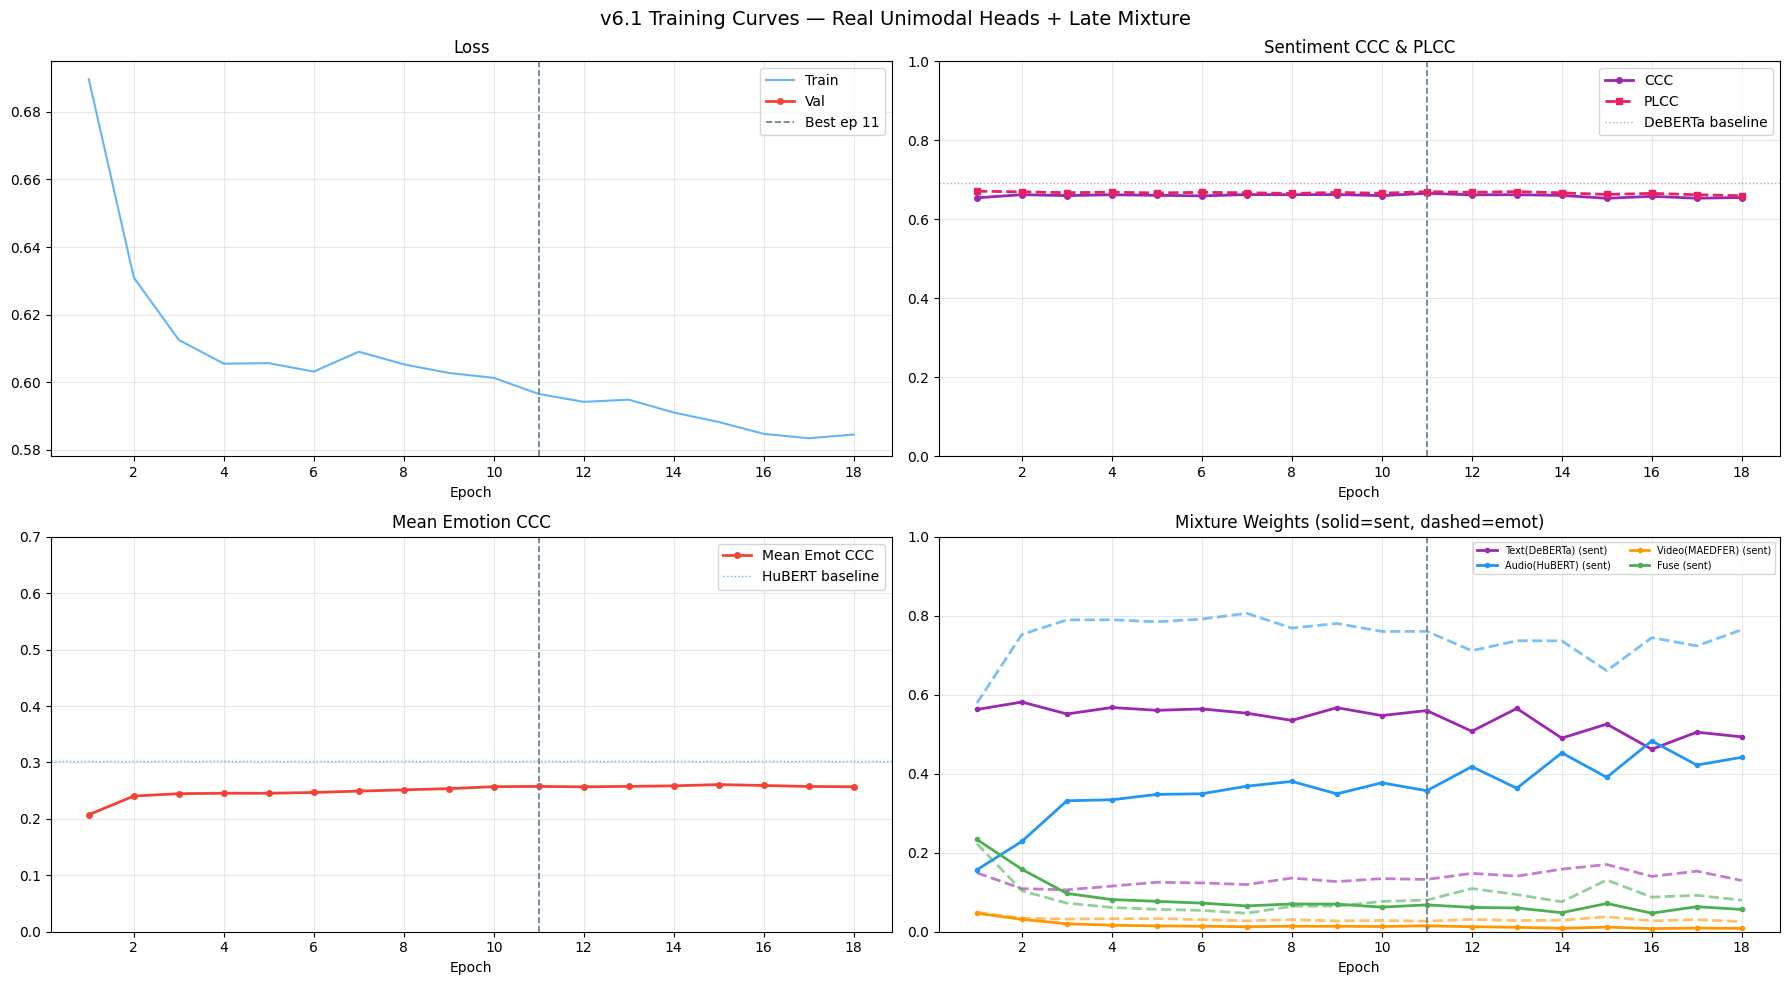

In [ ]:
# Training curves
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

C = {"text":"#9C27B0","audio":"#2196F3","video":"#FF9800","fuse":"#4CAF50",
     "combined":"#F44336","train":"#2196F3","val":"#F44336","best":"#607D8B"}

epochs_ran = range(1, len(history["train_loss"]) + 1)
w_sent_arr = np.array(history["w_sent"])
w_emot_arr = np.array(history["w_emot"])
MOD_LABELS = ["Text(DeBERTa)", "Audio(HuBERT)", "Video(MAEDFER)", "Fuse"]
mod_colors = [C["text"], C["audio"], C["video"], C["fuse"]]

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle("v6.1 Training Curves — Real Unimodal Heads + Late Mixture", fontsize=14)

ax = axes[0,0]
ax.plot(epochs_ran, history["train_loss"], color=C["train"], linewidth=1.5, alpha=0.7, label="Train")
ax.plot(epochs_ran, history["val_loss"],   color=C["val"],   linewidth=2, marker="o", markersize=4, label="Val")
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2, label=f"Best ep {best_epoch}")
ax.set_title("Loss"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

ax = axes[0,1]
ax.plot(epochs_ran, history["sent_ccc"],  color="#9C27B0", linewidth=2, marker="o", markersize=4, label="CCC")
ax.plot(epochs_ran, history["sent_plcc"], color="#E91E63", linewidth=2, marker="s", markersize=4, linestyle="--", label="PLCC")
ax.axhline(0.6918, color="#9C27B0", linestyle=":", linewidth=1, alpha=0.5, label="DeBERTa baseline")
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax.set_title("Sentiment CCC & PLCC"); ax.set_xlabel("Epoch"); ax.set_ylim(0, 1)
ax.legend(); ax.grid(True, alpha=0.3); ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

ax = axes[1,0]
ax.plot(epochs_ran, history["mean_emot_ccc"], color=C["combined"], linewidth=2, marker="o", markersize=4, label="Mean Emot CCC")
ax.axhline(0.3027, color=C["audio"], linestyle=":", linewidth=1, alpha=0.7, label="HuBERT baseline")
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax.set_title("Mean Emotion CCC"); ax.set_xlabel("Epoch"); ax.set_ylim(0, 0.7)
ax.legend(); ax.grid(True, alpha=0.3); ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

ax = axes[1,1]
for i,(label,color) in enumerate(zip(MOD_LABELS, mod_colors)):
    ax.plot(epochs_ran, w_sent_arr[:,i], color=color, linewidth=2, marker="o", markersize=3, label=f"{label} (sent)")
    ax.plot(epochs_ran, w_emot_arr[:,i], color=color, linewidth=2, linestyle="--", alpha=0.6)
ax.set_title("Mixture Weights (solid=sent, dashed=emot)")
ax.set_xlabel("Epoch"); ax.set_ylim(0,1); ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/v61_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


Test-set average gate weights:
  Sentiment [text, audio, video, fuse]: [0.563 0.343 0.017 0.077]
  Emotion   [text, audio, video, fuse]: [0.152 0.694 0.034 0.12 ]


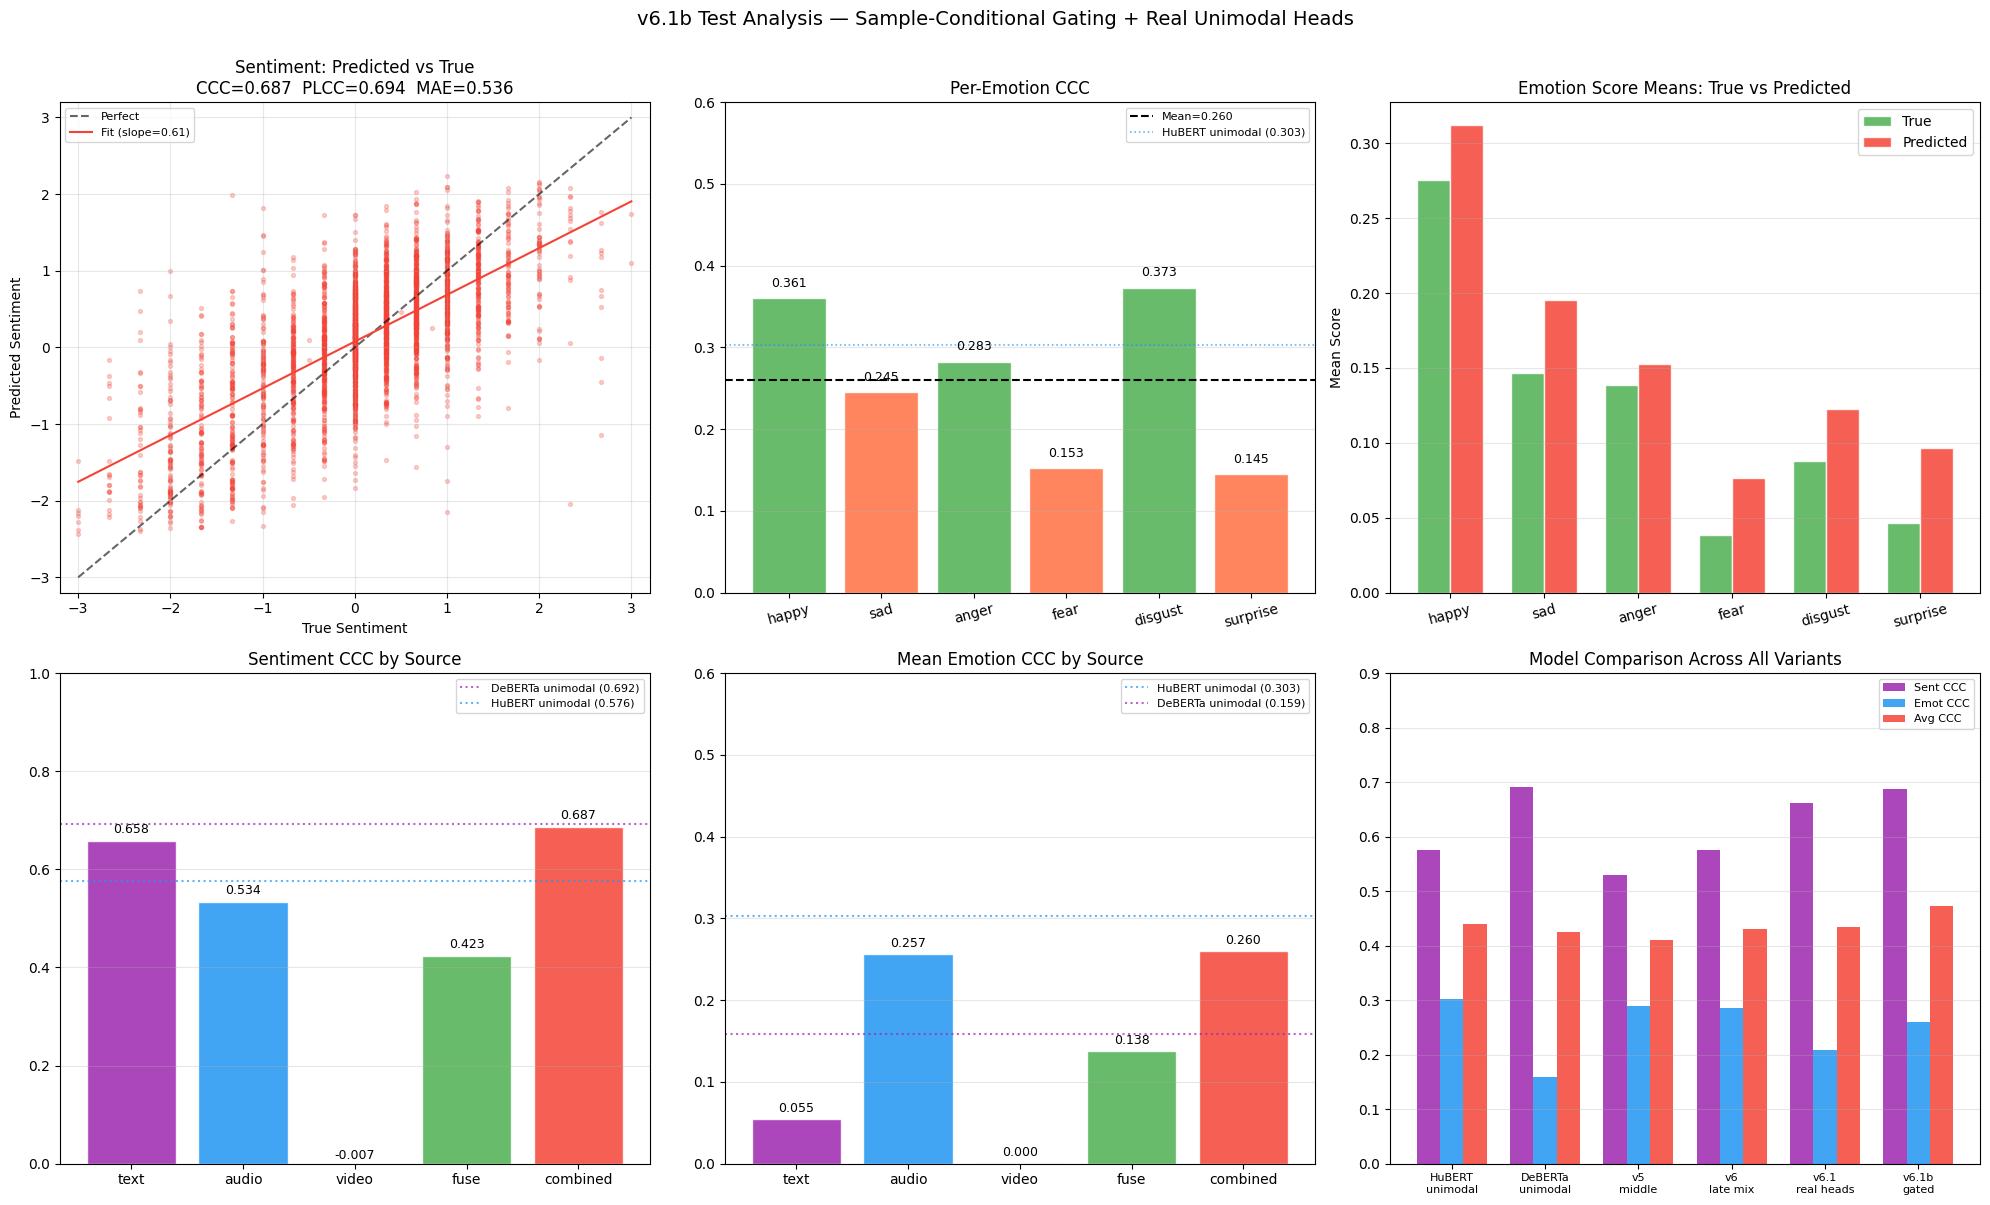

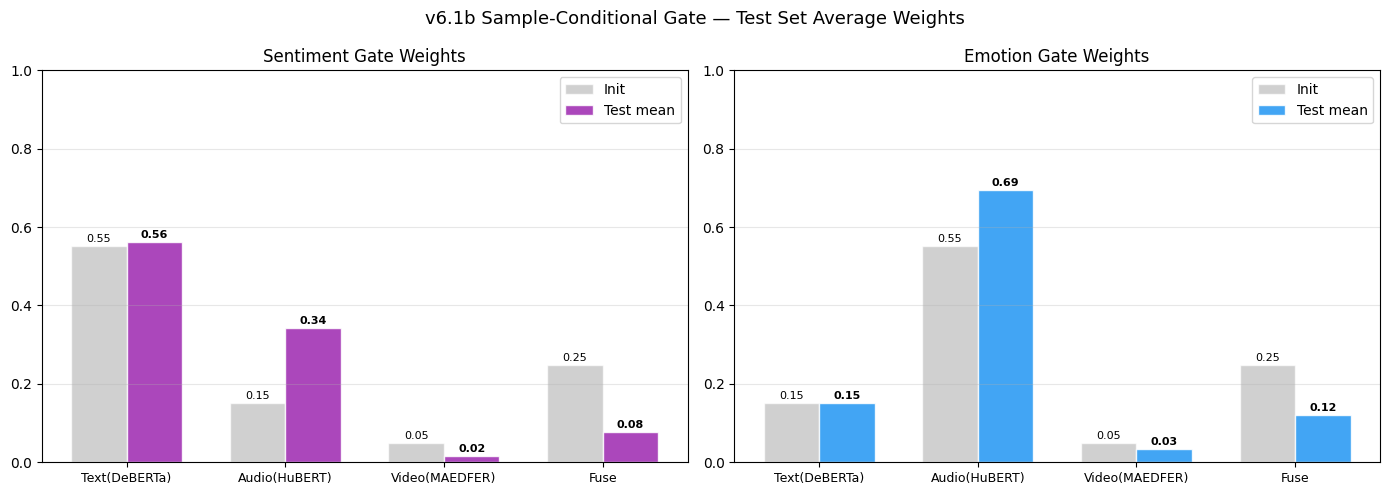

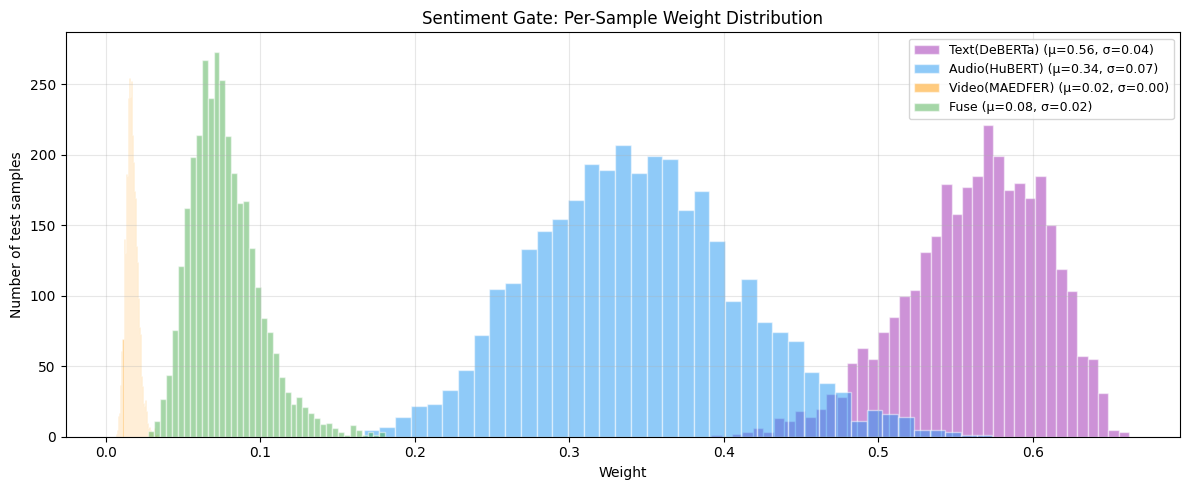


Figures saved to /content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v61-clean


In [ ]:
# Cell 13: Test set visualizations + gate weight analysis
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Compute test-set average gate weights (more informative than last batch)
fusion.eval()
all_w_sent, all_w_emot = [], []
with torch.no_grad():
    for batch in test_loader:
        tf, vf, af = extract_features(batch)
        sent_t, emot_t = deberta_aux(tf)
        sent_a, emot_a = hubert_aux(af)
        sent_v, emot_v = maedfer_aux(vf)
        _, _, _, aux_full = fusion(
            tf, vf, af, sent_t, emot_t, sent_a, emot_a, sent_v, emot_v,
            batch["sentiment_labels"].to(device), batch["emotion_labels"].to(device),
            emotion_weights=EMOTION_WEIGHTS)
        all_w_sent.append(aux_full["w_sent"].cpu().numpy())
        all_w_emot.append(aux_full["w_emot"].cpu().numpy())

mean_w_sent = np.mean(all_w_sent, axis=0)
mean_w_emot = np.mean(all_w_emot, axis=0)
print(f"Test-set average gate weights:")
print(f"  Sentiment [text, audio, video, fuse]: {mean_w_sent.round(3)}")
print(f"  Emotion   [text, audio, video, fuse]: {mean_w_emot.round(3)}")

# 2. Extract data for plotting
sent_true  = np.array(test['sent_true'])
sent_preds = np.array(test['sent_pred'])
emot_true  = test['emot_true']
emot_preds = test['emot_pred']

C = {"text":"#9C27B0","audio":"#2196F3","video":"#FF9800","fuse":"#4CAF50",
     "combined":"#F44336","best":"#607D8B"}

fig = plt.figure(figsize=(20, 12))
fig.suptitle(f"v6.1b Test Analysis — Sample-Conditional Gating + Real Unimodal Heads",
             fontsize=14, y=1.00)

# Panel 1: Sentiment scatter (predicted vs true)
ax1 = fig.add_subplot(2, 3, 1)
ax1.scatter(sent_true, sent_preds, alpha=0.25, s=8, color=C["combined"], rasterized=True)
ax1.plot([-3, 3], [-3, 3], "k--", linewidth=1.5, alpha=0.6, label="Perfect")
m, b = np.polyfit(sent_true, sent_preds, 1)
ax1.plot([-3, 3], [m*-3 + b, m*3 + b], color=C["combined"], linewidth=1.5,
         label=f"Fit (slope={m:.2f})")
ax1.set_title(f"Sentiment: Predicted vs True\nCCC={test['sent_ccc']:.3f}  "
              f"PLCC={test['sent_plcc']:.3f}  MAE={test['sent_mae']:.3f}")
ax1.set_xlabel("True Sentiment"); ax1.set_ylabel("Predicted Sentiment")
ax1.set_xlim(-3.2, 3.2); ax1.set_ylim(-3.2, 3.2)
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)

# Panel 2: Per-emotion CCC
ax2 = fig.add_subplot(2, 3, 2)
bar_colors = ["#4CAF50" if c >= test["mean_emot_ccc"] else "#FF7043"
              for c in test["emot_ccc_scores"]]
bars = ax2.bar(EMOTION_COLS, test["emot_ccc_scores"], color=bar_colors,
                alpha=0.85, edgecolor="white")
ax2.axhline(test["mean_emot_ccc"], color="black", linestyle="--", linewidth=1.5,
            label=f"Mean={test['mean_emot_ccc']:.3f}")
ax2.axhline(0.3027, color=C["audio"], linestyle=":", linewidth=1.2, alpha=0.7,
            label="HuBERT unimodal (0.303)")
for bar, val in zip(bars, test["emot_ccc_scores"]):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
              f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax2.set_title("Per-Emotion CCC")
ax2.set_ylim(0, 0.6); ax2.tick_params(axis="x", rotation=15)
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3, axis="y")

# Panel 3: True vs predicted emotion means
ax3 = fig.add_subplot(2, 3, 3)
x = np.arange(len(EMOTION_COLS)); w = 0.35
ax3.bar(x - w/2, emot_true.mean(axis=0), w, label="True",
         color="#4CAF50", alpha=0.85, edgecolor="white")
ax3.bar(x + w/2, emot_preds.mean(axis=0), w, label="Predicted",
         color=C["combined"], alpha=0.85, edgecolor="white")
ax3.set_xticks(x); ax3.set_xticklabels(EMOTION_COLS, rotation=15)
ax3.set_title("Emotion Score Means: True vs Predicted")
ax3.set_ylabel("Mean Score")
ax3.legend(); ax3.grid(True, alpha=0.3, axis="y")

# Panel 4: Sentiment CCC per source + combined
ax4 = fig.add_subplot(2, 3, 4)
mod_keys = ["text", "audio", "video", "fuse", "combined"]
mod_cols = [C["text"], C["audio"], C["video"], C["fuse"], C["combined"]]
s_cccs = [ccc_np(sent_true, test["per_mod_sent"][m])[0]
          for m in ["text", "audio", "video", "fuse"]]
s_cccs.append(test["sent_ccc"])
bars4 = ax4.bar(mod_keys, s_cccs, color=mod_cols, alpha=0.85, edgecolor="white")
ax4.axhline(0.6918, color=C["text"], linestyle=":", linewidth=1.5, alpha=0.7,
            label="DeBERTa unimodal (0.692)")
ax4.axhline(0.5756, color=C["audio"], linestyle=":", linewidth=1.5, alpha=0.7,
            label="HuBERT unimodal (0.576)")
for bar, val in zip(bars4, s_cccs):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
              f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax4.set_title("Sentiment CCC by Source")
ax4.set_ylim(0, 1.0); ax4.legend(fontsize=8); ax4.grid(True, alpha=0.3, axis="y")

# Panel 5: Emotion CCC per source + combined
ax5 = fig.add_subplot(2, 3, 5)
e_cccs = []
for mod in ["text", "audio", "video", "fuse"]:
    pred_arr = np.array(test["per_mod_emot"][mod])
    per_emo  = [ccc_np(emot_true[:, i], pred_arr[:, i])[0] for i in range(6)]
    e_cccs.append(np.mean(per_emo))
e_cccs.append(test["mean_emot_ccc"])
bars5 = ax5.bar(mod_keys, e_cccs, color=mod_cols, alpha=0.85, edgecolor="white")
ax5.axhline(0.3027, color=C["audio"], linestyle=":", linewidth=1.5, alpha=0.7,
            label="HuBERT unimodal (0.303)")
ax5.axhline(0.1587, color=C["text"], linestyle=":", linewidth=1.5, alpha=0.7,
            label="DeBERTa unimodal (0.159)")
for bar, val in zip(bars5, e_cccs):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
              f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax5.set_title("Mean Emotion CCC by Source")
ax5.set_ylim(0, 0.6); ax5.legend(fontsize=8); ax5.grid(True, alpha=0.3, axis="y")

# Panel 6: Model comparison
ax6 = fig.add_subplot(2, 3, 6)
models = ["HuBERT\nunimodal", "DeBERTa\nunimodal", "v5\nmiddle", "v6\nlate mix",
          "v6.1\nreal heads", "v6.1b\ngated"]
sccc_v = [0.5756, 0.6918, 0.5302, 0.5762, 0.6610, test["sent_ccc"]]
eccc_v = [0.3027, 0.1587, 0.2900, 0.2851, 0.2081, test["mean_emot_ccc"]]
avg_v  = [(s + e) / 2 for s, e in zip(sccc_v, eccc_v)]
x6 = np.arange(len(models)); w6 = 0.25
ax6.bar(x6 - w6, sccc_v, w6, label="Sent CCC", color="#9C27B0", alpha=0.85)
ax6.bar(x6,      eccc_v, w6, label="Emot CCC", color=C["audio"], alpha=0.85)
ax6.bar(x6 + w6, avg_v,  w6, label="Avg CCC",  color=C["combined"], alpha=0.85)
ax6.set_xticks(x6); ax6.set_xticklabels(models, fontsize=8)
ax6.set_title("Model Comparison Across All Variants")
ax6.set_ylim(0, 0.9); ax6.legend(fontsize=8); ax6.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/v61b_test_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Gate weights visualization
fig2, axes = plt.subplots(1, 2, figsize=(14, 5))
fig2.suptitle("v6.1b Sample-Conditional Gate — Test Set Average Weights", fontsize=13)

mod_labels = ["Text(DeBERTa)", "Audio(HuBERT)", "Video(MAEDFER)", "Fuse"]
gate_colors = [C["text"], C["audio"], C["video"], C["fuse"]]

# Sentiment gate
init_sent = F.softmax(torch.tensor(MIXTURE_INIT_SENT), dim=0).numpy()
x_g = np.arange(4); w_g = 0.35
axes[0].bar(x_g - w_g/2, init_sent, w_g, label="Init", color="#BDBDBD", alpha=0.7, edgecolor="white")
axes[0].bar(x_g + w_g/2, mean_w_sent, w_g, label="Test mean", color=gate_colors[0],
            alpha=0.85, edgecolor="white")
for i, (v_init, v_test) in enumerate(zip(init_sent, mean_w_sent)):
    axes[0].text(i - w_g/2, v_init + 0.01, f"{v_init:.2f}", ha="center", fontsize=8)
    axes[0].text(i + w_g/2, v_test + 0.01, f"{v_test:.2f}", ha="center", fontsize=8, weight='bold')
axes[0].set_xticks(x_g); axes[0].set_xticklabels(mod_labels, fontsize=9)
axes[0].set_title("Sentiment Gate Weights"); axes[0].set_ylim(0, 1)
axes[0].legend(); axes[0].grid(True, alpha=0.3, axis="y")

# Emotion gate
init_emot = F.softmax(torch.tensor(MIXTURE_INIT_EMOT), dim=0).numpy()
axes[1].bar(x_g - w_g/2, init_emot, w_g, label="Init", color="#BDBDBD", alpha=0.7, edgecolor="white")
axes[1].bar(x_g + w_g/2, mean_w_emot, w_g, label="Test mean", color=gate_colors[1],
            alpha=0.85, edgecolor="white")
for i, (v_init, v_test) in enumerate(zip(init_emot, mean_w_emot)):
    axes[1].text(i - w_g/2, v_init + 0.01, f"{v_init:.2f}", ha="center", fontsize=8)
    axes[1].text(i + w_g/2, v_test + 0.01, f"{v_test:.2f}", ha="center", fontsize=8, weight='bold')
axes[1].set_xticks(x_g); axes[1].set_xticklabels(mod_labels, fontsize=9)
axes[1].set_title("Emotion Gate Weights"); axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/v61b_gate_weights.png", dpi=150, bbox_inches="tight")
plt.show()

# Sample-level gate variability (sentiment only, for brevity)
# Show how much per-sample gate weights deviate from the test-set mean
fig3, ax = plt.subplots(figsize=(12, 5))
fusion.eval()
sample_weights_sent = []
with torch.no_grad():
    for batch in test_loader:
        tf, vf, af = extract_features(batch)
        t = fusion.text_proj(tf)
        a = fusion.audio_proj(af)
        v = fusion.video_proj(vf.unsqueeze(1) if vf.dim() == 2 else vf)
        t_pool = fusion.text_pool(t)
        a_pool = fusion.audio_pool(a)
        v_pool = fusion.video_norm(v).expand(-1, POOL_LEN, -1)
        w_s = fusion.sent_gate(t_pool, a_pool, v_pool)
        sample_weights_sent.append(w_s.cpu().numpy())

sample_weights_sent = np.concatenate(sample_weights_sent, axis=0)
for i, (label, color) in enumerate(zip(mod_labels, gate_colors)):
    ax.hist(sample_weights_sent[:, i], bins=40, alpha=0.5, color=color,
             label=f"{label} (μ={sample_weights_sent[:,i].mean():.2f}, "
                   f"σ={sample_weights_sent[:,i].std():.2f})", edgecolor="white")
ax.set_title("Sentiment Gate: Per-Sample Weight Distribution")
ax.set_xlabel("Weight"); ax.set_ylabel("Number of test samples")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/v61b_gate_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nFigures saved to {OUTPUT_DIR}")